# CVRP: Exact MILP vs Heuristic

We solve the CVRP in two ways: an exact MILP model and a Simulated Annealing heuristic.
Then we compare them. All the code is in `src/`.

In [1]:
import math
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# project root = the folder that contains src/ and data/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import common
from loader import load_cvrplib
from model_milp import build_model, solve
from plots import plot_routes
from IPython.display import Image, display

DATA = ROOT / "data" / "instances"
print("project root:", ROOT)
print("instances:", sorted(p.name for p in DATA.glob("*.vrp")))


project root: /Users/nisalgangana/Documents/SLIIT/Y1S2/Optimization/optimization-assignment-cvrp
instances: ['A-n32-k5.vrp', 'A-n45-k6.vrp', 'A-n80-k10.vrp', 'E-n22-k4.vrp', 'P-n16-k8.vrp']


## 1. Data

We use 5 instances from CVRPLIB. Each one has a known optimal cost.
"min vehicles" is the smallest number of trucks needed. "fill rate" shows how full the fleet is.

In [2]:
NAMES = ["P-n16-k8", "E-n22-k4", "A-n32-k5", "A-n45-k6", "A-n80-k10"]
instances = {name: load_cvrplib(DATA / f"{name}.vrp") for name in NAMES}

rows = []
for name, inst in instances.items():
    total = int(inst.demand.sum())
    rows.append({
        "instance": name,
        "customers (n)": inst.n_customers,
        "vehicles (K)": inst.n_vehicles,
        "capacity (Q)": inst.capacity,
        "total demand": total,
        "min vehicles": math.ceil(total / inst.capacity),
        "fill rate": round(total / (inst.n_vehicles * inst.capacity), 2),
        "optimum": inst.optimum,
    })
data_table = pd.DataFrame(rows).set_index("instance")
data_table


,customers (n),vehicles (K),capacity (Q),total demand,min vehicles,fill rate,optimum
instance,,,,,,,
P-n16-k8,15,8,35,246,8,0.88,450
E-n22-k4,21,4,6000,22500,4,0.94,375
A-n32-k5,31,5,100,410,5,0.82,784
A-n45-k6,44,6,100,593,6,0.99,944
A-n80-k10,79,10,100,942,10,0.94,1763


In every instance, min vehicles = K, so there is no spare truck.
The fill rate is high (0.82 to 0.99). This makes the problems hard.
The plot shows P-n16-k8. The red square is the depot. Bigger dots mean bigger demand.

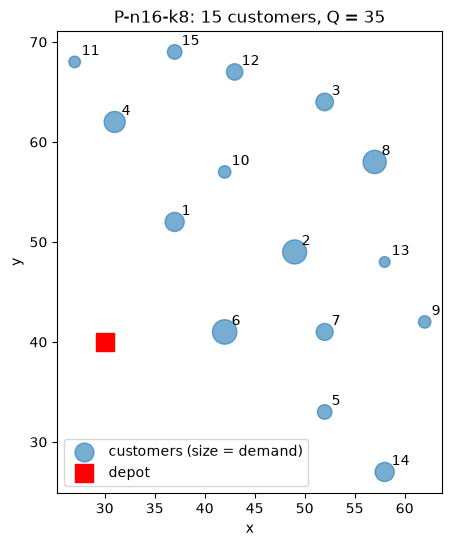

In [3]:
inst = instances["P-n16-k8"]
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(inst.coords[1:, 0], inst.coords[1:, 1], s=inst.demand[1:] * 10,
           alpha=0.6, label="customers (size = demand)")
ax.scatter(*inst.coords[0], marker="s", s=150, color="red", label="depot")
for i in inst.customers:
    ax.annotate(str(i), inst.coords[i], textcoords="offset points", xytext=(5, 5))
ax.set_title(f"{inst.name}: {inst.n_customers} customers, Q = {inst.capacity}")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend()
ax.set_aspect("equal")
plt.show()


## 2. Exact method: how big is the model?

Here we only build the model, without solving it, and count the variables and constraints.

In [4]:
rows = []
for name, inst in instances.items():
    t0 = time.perf_counter()
    prob, x, u = build_model(inst)
    build_time = time.perf_counter() - t0
    n = inst.n_customers
    rows.append({
        "instance": name,
        "customers (n)": n,
        "binary x": len(x),
        "continuous u": len(u),
        "variables": prob.numVariables(),
        "constraints": prob.numConstraints(),
        "MTZ (C4)": n * (n - 1),
        "build time (s)": round(build_time, 2),
    })
size_table = pd.DataFrame(rows).set_index("instance")
size_table


,customers (n),binary x,continuous u,variables,constraints,MTZ (C4),build time (s)
instance,,,,,,,
P-n16-k8,15,240,15,255,272,210,0.00
E-n22-k4,21,462,21,483,506,420,0.00
A-n32-k5,31,992,31,1023,1056,930,0.01
A-n45-k6,44,1980,44,2024,2070,1892,0.01
A-n80-k10,79,6320,79,6399,6480,6162,0.04


The number of customers grows about 5 times (15 → 79), but the number of variables grows about 25 times (255 → 6,399).
Building the model is fast (under 1 second). Solving it is the hard part.

## 3. Exact method: solving the instances

We solve P-n16-k8 here with a 120-second limit. It takes about 1 minute.

In [5]:
p_inst = instances["P-n16-k8"]
p_sol = solve(p_inst, time_limit=120)
print(common.describe(p_inst, p_sol))
print(f"  lower bound = {p_sol.bound}")


P-n16-k8  method=milp  status=optimal
  cost=450  optimum=450  gap=0.00%
  runtime=66.28s  feasible=True (ok)
  route 0: 0 -> 2 -> 0  (load 30/35, dist 42)
  route 1: 0 -> 3 -> 1 -> 0  (load 35/35, dist 66)
  route 2: 0 -> 5 -> 14 -> 0  (load 30/35, dist 62)
  route 3: 0 -> 6 -> 0  (load 31/35, dist 24)
  route 4: 0 -> 7 -> 9 -> 13 -> 0  (load 29/35, dist 68)
  route 5: 0 -> 8 -> 0  (load 28/35, dist 64)
  route 6: 0 -> 10 -> 12 -> 15 -> 0  (load 33/35, dist 67)
  route 7: 0 -> 11 -> 4 -> 0  (load 30/35, dist 57)
  lower bound = 450.0


saved results/figures/routes_P-n16-k8_milp.png


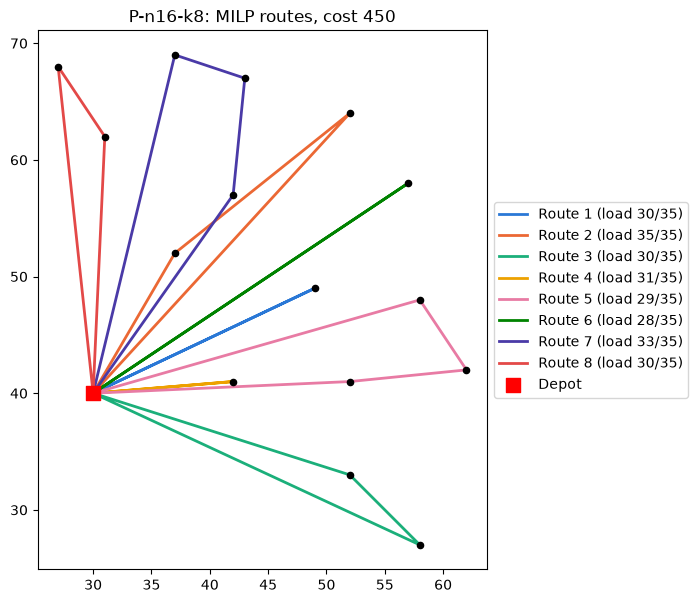

In [6]:
fig = plot_routes(p_inst, p_sol)

The MILP proves that 450 is optimal. All 8 trucks are used, and some are completely full.
With a 60-second limit, CBC finds 450 but cannot prove it is optimal. Proving takes longer than finding.

The other runs take 10 minutes each, so we load them from `results/results.csv` (made by `src/evaluate.py`).
MIP gap = (cost − lower bound) / cost. It shows how unsure the solver still is.

In [7]:
results = pd.read_csv(ROOT / "results" / "results.csv")

milp = results[results["method"] == "milp"].set_index("instance")
milp_table = pd.DataFrame({
    "customers (n)": milp["n"],
    "status": milp["status"],
    "cost": milp["cost"],
    "optimum": milp["optimum"],
    "gap to optimum (%)": milp["gap_pct"],
    "lower bound": milp["bound"].round(1),
    "MIP gap (%)": (100 * (milp["cost"] - milp["bound"]) / milp["cost"]).round(1),
    "runtime (s)": milp["runtime_s"].round(1),
})
milp_table


,customers (n),status,cost,optimum,gap to optimum (%),lower bound,MIP gap (%),runtime (s)
instance,,,,,,,,
P-n16-k8,15,optimal,450.0,450.0,0.00,450.0,0.0,68.9
E-n22-k4,21,timeout,466.0,375.0,24.27,261.3,43.9,600.4
A-n32-k5,31,timeout,1144.0,784.0,45.92,424.0,62.9,600.8
A-n45-k6,44,timeout,1557.0,944.0,64.94,504.0,67.6,601.3
A-n80-k10,79,timeout,inf,1763.0,NaN,711.9,NaN,600.4
synth-n10-k2-s0,10,optimal,365.0,NaN,NaN,365.0,0.0,1.3
synth-n20-k3-s0,20,timeout,542.0,NaN,NaN,426.0,21.4,600.6
synth-n40-k7-s0,40,timeout,1213.0,NaN,NaN,515.8,57.5,600.6
synth-n80-k14-s0,80,timeout,2223.0,NaN,NaN,659.2,70.3,600.5


Only the small instances (10 and 15 customers) are solved to optimality. From 20 customers, the MILP always hits the time limit.
The reason is the weak lower bound. On E-n22-k4 it stayed at 261 for the whole 10 minutes (optimum: 375).
Because of the MTZ big-M term, the LP relaxation is weak, so branch and bound cannot cut enough branches.

## 4. Exact vs heuristic

SA is random, so it was run 5 times (5 seeds). The table shows the best, mean and std of these runs. The MILP was run once.

In [8]:
sa = results[results["method"] == "sa"].groupby("instance", sort=False)

comparison = pd.DataFrame({
    "customers (n)": milp["n"],
    "optimum": milp["optimum"],
    "MILP cost": milp["cost"],
    "MILP status": milp["status"],
    "MILP time (s)": milp["runtime_s"].round(1),
    "SA best": sa["cost"].min(),
    "SA mean": sa["cost"].mean().round(1),
    "SA std": sa["cost"].std().round(1),
    "SA time (s)": sa["runtime_s"].mean().round(1),
})
comparison["SA mean gap (%)"] = (
    100 * (comparison["SA mean"] - comparison["optimum"]) / comparison["optimum"]
).round(2)
comparison


,customers (n),optimum,MILP cost,MILP status,MILP time (s),SA best,SA mean,SA std,SA time (s),SA mean gap (%)
instance,,,,,,,,,,
P-n16-k8,15,450.0,450.0,optimal,68.9,450.0,450.0,0.0,0.5,0.00
E-n22-k4,21,375.0,466.0,timeout,600.4,375.0,379.6,4.2,0.9,1.23
A-n32-k5,31,784.0,1144.0,timeout,600.8,784.0,801.8,24.4,2.0,2.27
A-n45-k6,44,944.0,1557.0,timeout,601.3,1009.0,1075.8,70.3,3.1,13.96
A-n80-k10,79,1763.0,inf,timeout,600.4,1835.0,1852.4,17.9,7.7,5.07
synth-n10-k2-s0,10,NaN,365.0,optimal,1.3,365.0,365.0,0.0,0.4,NaN
synth-n20-k3-s0,20,NaN,542.0,timeout,600.6,530.0,534.8,4.8,1.1,NaN
synth-n40-k7-s0,40,NaN,1213.0,timeout,600.6,843.0,858.8,12.5,2.4,NaN
synth-n80-k14-s0,80,NaN,2223.0,timeout,600.5,1453.0,1490.6,26.4,7.3,NaN


- Both methods find 450 on P-n16-k8, but SA takes 0.5 s and the MILP takes 69 s.
- SA finds the exact optimum on E-n22-k4 and A-n32-k5 in 1–2 seconds. The MILP does not, even in 10 minutes.
- SA's mean gap is under about 5%, except on A-n45-k6 (14%). This instance is the fullest (fill rate 0.99).
- On A-n80-k10, the MILP finds no solution in 10 minutes. SA finds one in 8 seconds.

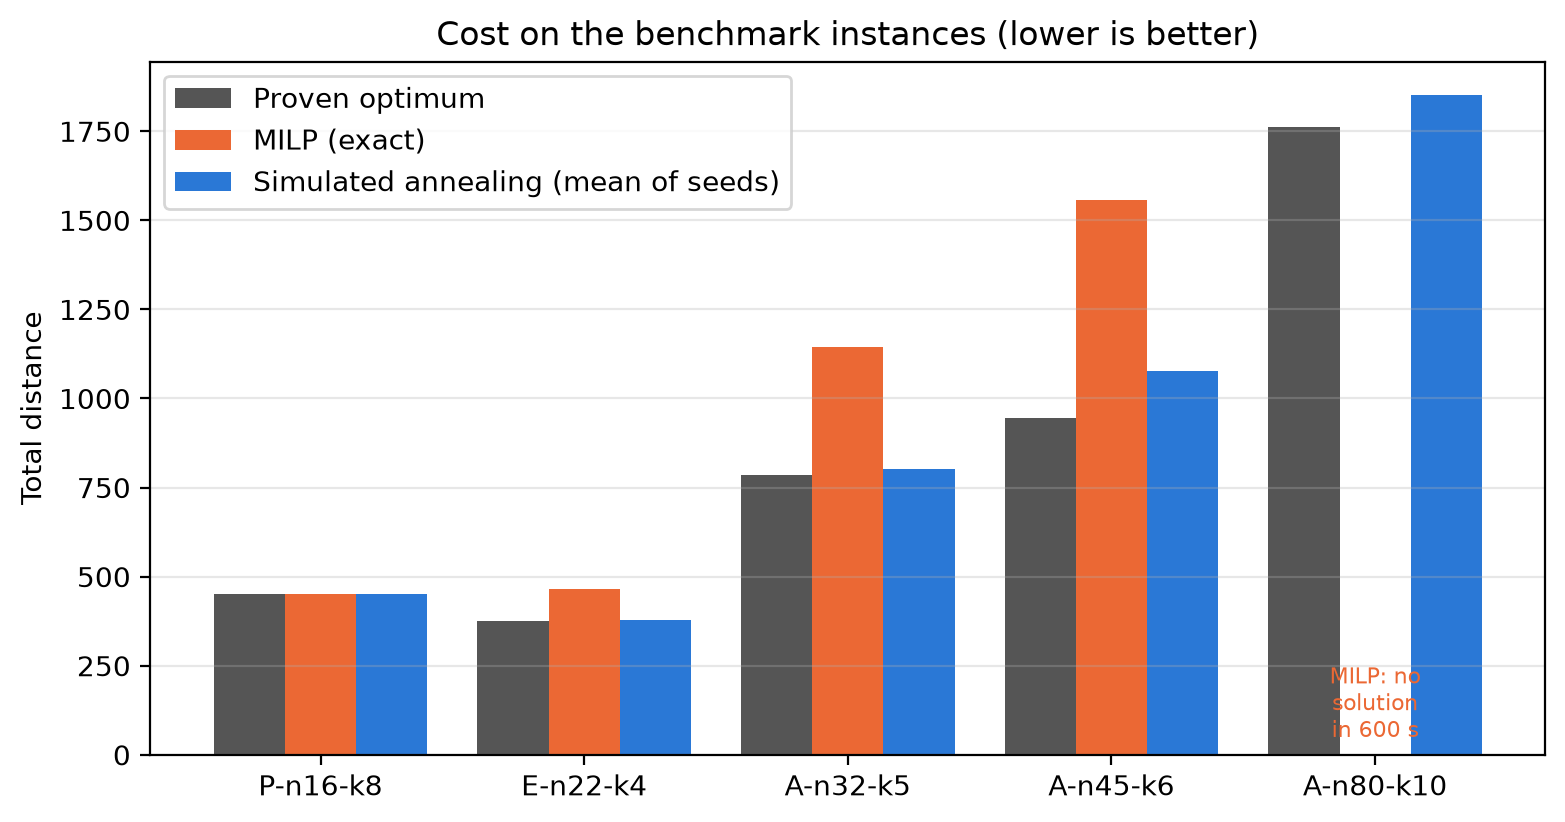

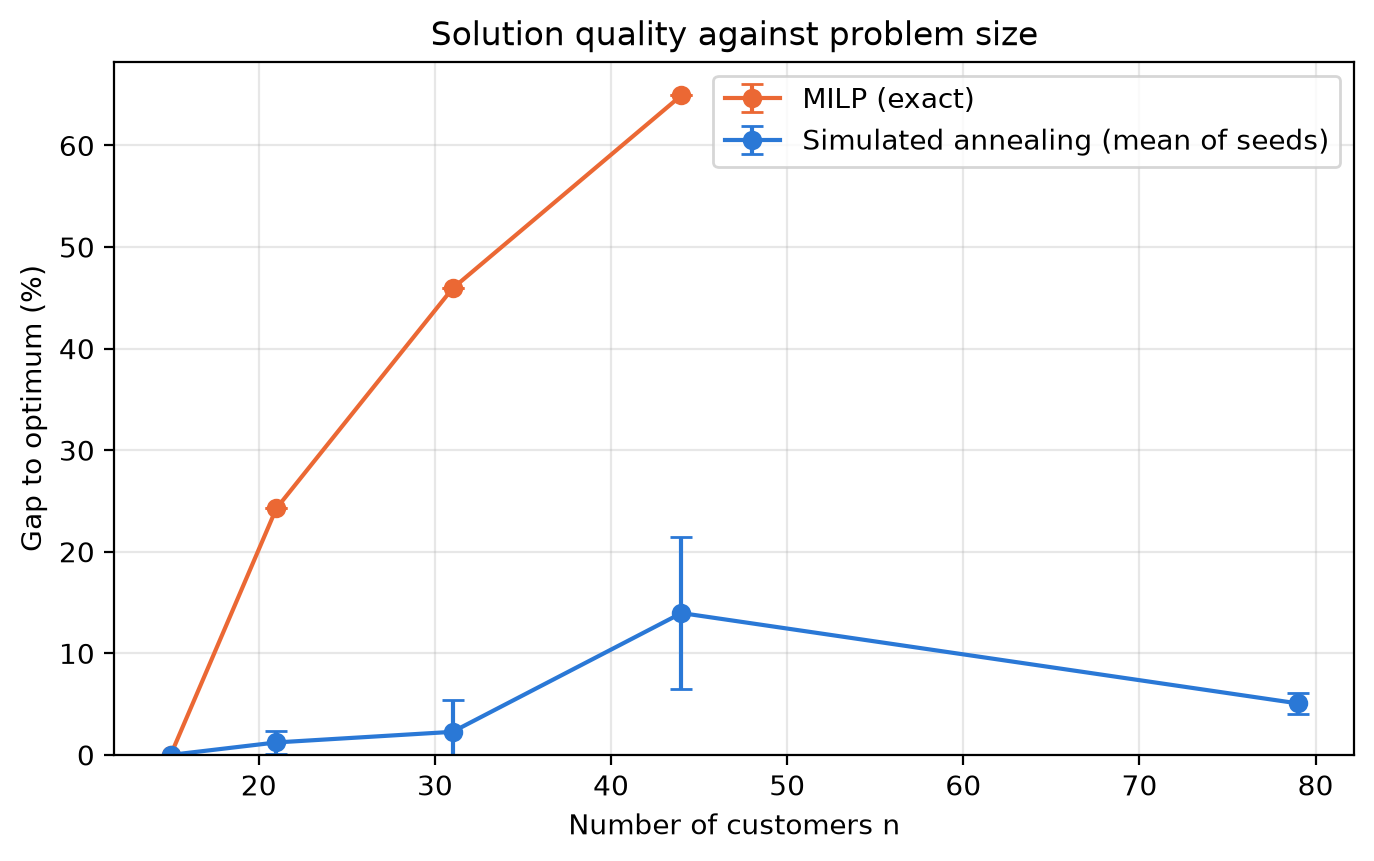

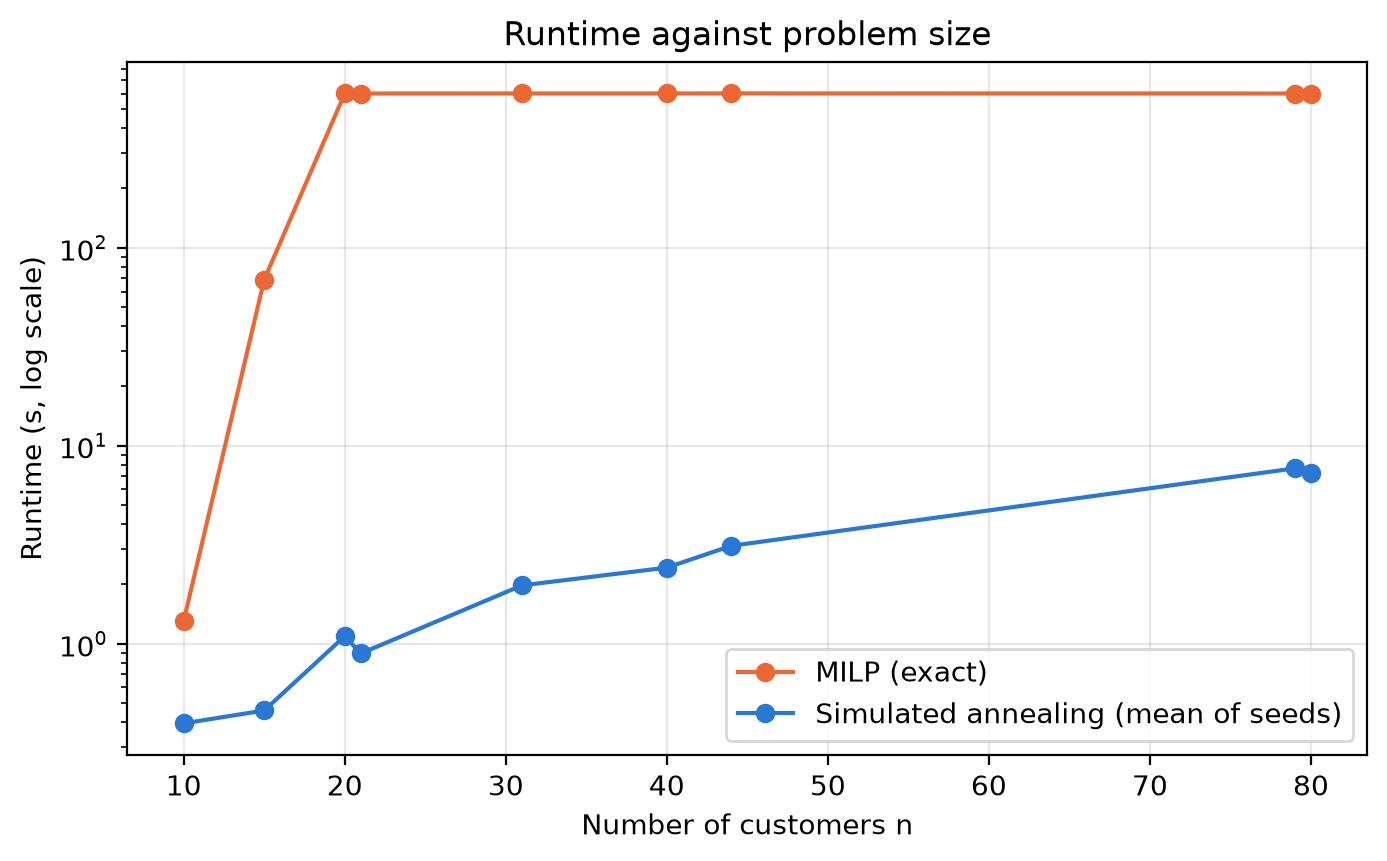

In [9]:
FIGURES = ROOT / "results" / "figures"
for name in ["cost_comparison.png", "gap_vs_n.png", "runtime_vs_n.png"]:
    display(Image(filename=str(FIGURES / name), width=700))


The charts show cost, gap and runtime. The MILP reaches the 600 s limit from n = 20. SA stays under 8 seconds.
Below is one SA solution for A-n32-k5 (cost 828).

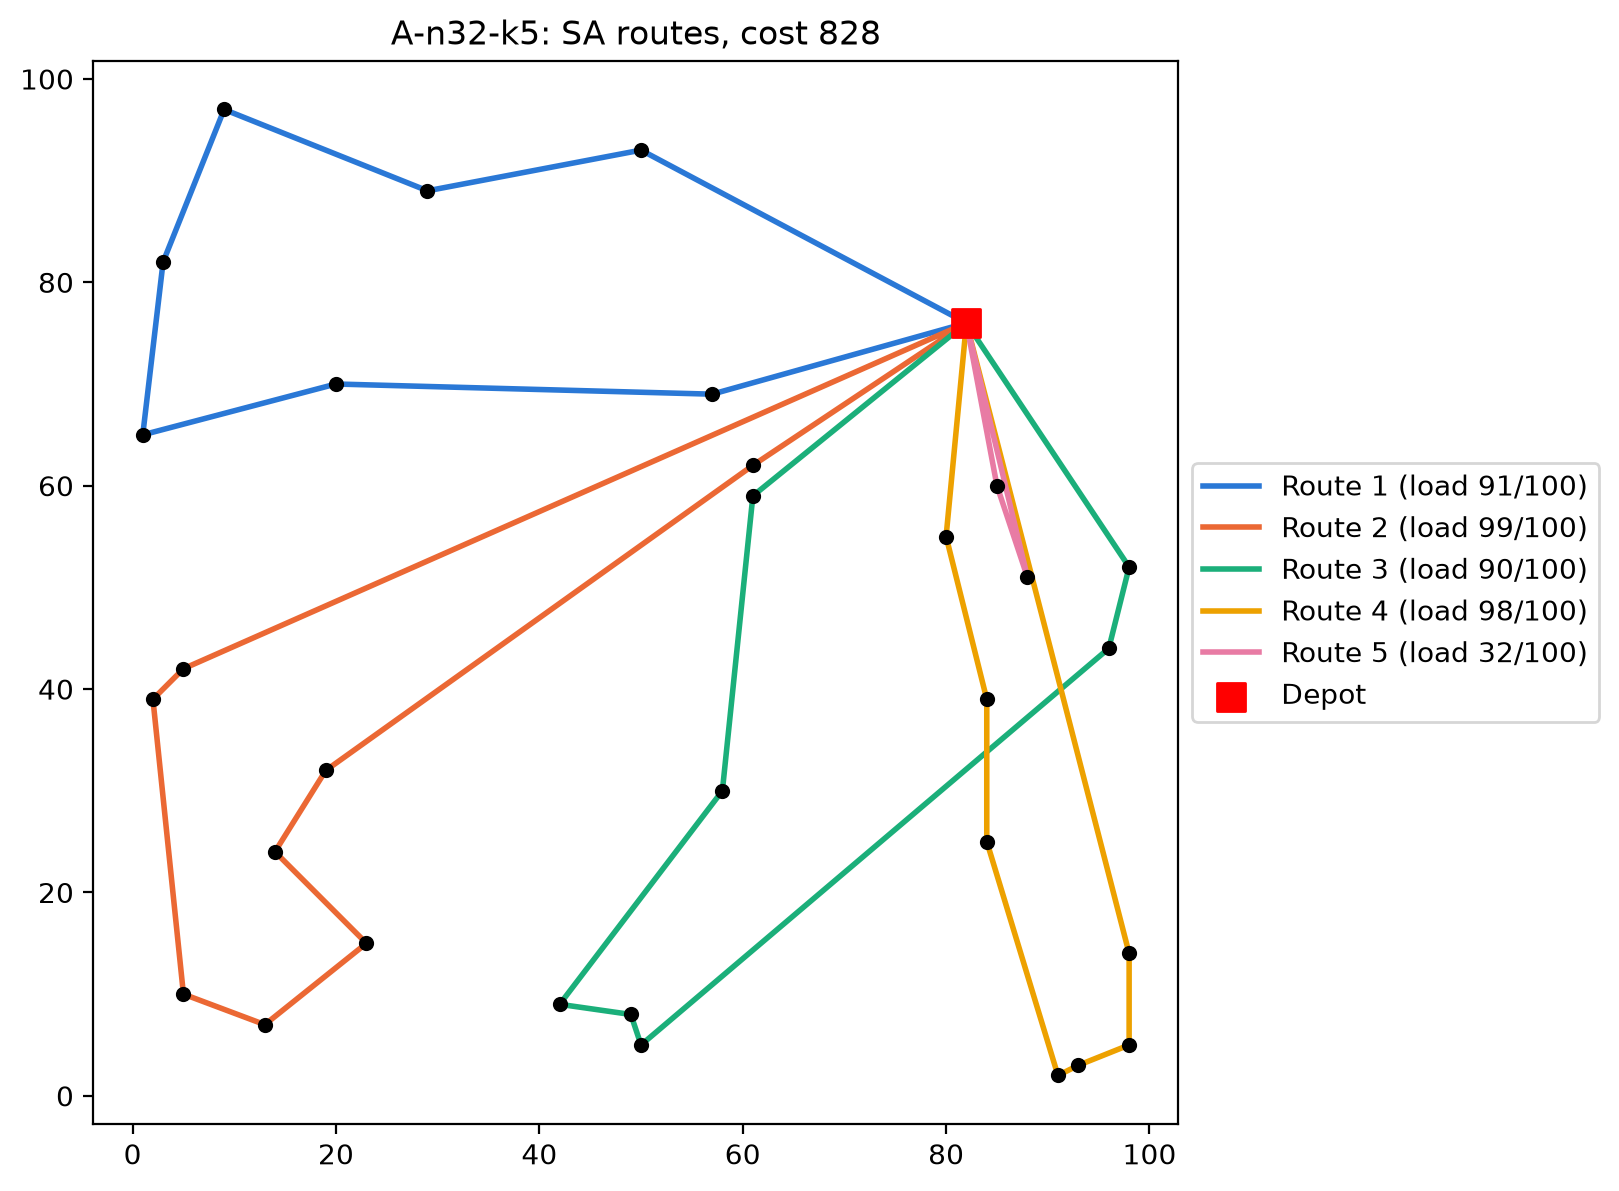

In [10]:
display(Image(filename=str(FIGURES / "routes_A-n32-k5_sa.png"), width=600))


## 5. Conclusion

- The MILP is correct and gives proven optimal solutions, but only for small instances (about 15 customers).
- SA gives near-optimal solutions in seconds, but it cannot prove they are optimal.
- So the two methods work well together. A stronger MILP formulation or an SA warm start could help in future work.